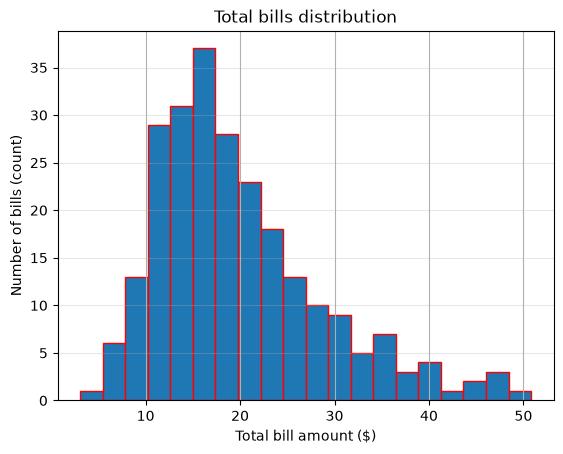

In [37]:
# 1. Гістограма розподілу рахунків
# Створіть гістограму для колонки total_bill з 20 bins. Опціонально можна додати підписи осей ОХ, ОУ, а також назву графіку.
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

df = pd.read_csv("tip.csv")

df["total_bill"].hist(bins=20, edgecolor="red")
plt.title("Total bills distribution")
plt.xlabel("Total bill amount ($)")
plt.ylabel("Number of bills (count)")
plt.grid(axis='y', alpha=0.3)
plt.show()

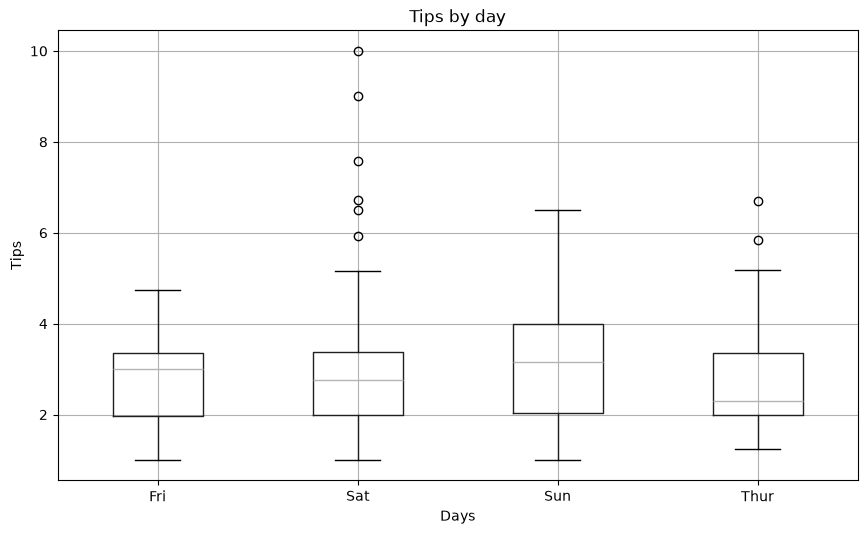

In [13]:
# 2. Box plot чайових за днями тижня
# Створіть box plot, який показує розподіл чайових (tip) за днями тижня (day).
df.boxplot(column="tip", by="day", figsize=(10,6))
plt.title("Tips by day")
plt.suptitle('')
plt.xlabel("Days")
plt.ylabel("Tips")
plt.show()

In [14]:
# В який день навище медіанне значення чайоивх? Зелена горизонтальна лінія всередині кожного box-plot.
print(f"The biggest median by day:")
display(df.groupby(["day"])["tip"].median().sort_values(ascending=False))

The biggest median by day:


day
Sun     3.150
Fri     3.000
Sat     2.750
Thur    2.305
Name: tip, dtype: float64

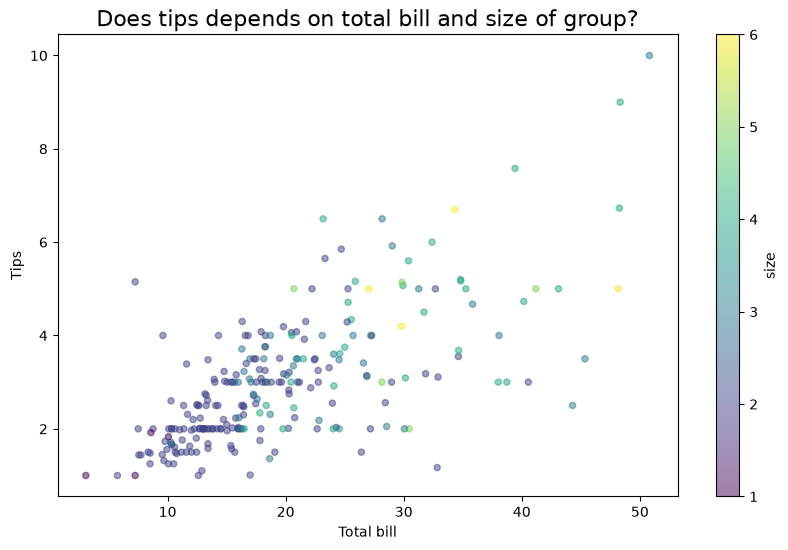

In [36]:
# 3. Scatter plot: рахунок vs чайові
# Створіть діаграму розсіювання для total_bill та tip.
df.plot.scatter(x="total_bill", y="tip", alpha=0.5, c="size", figsize=(10, 6), colormap="viridis")
plt.title("Does tips depends on total bill and size of group?", fontsize=16)
plt.suptitle('')
plt.xlabel("Total bill")
plt.ylabel("Tips")
plt.show()

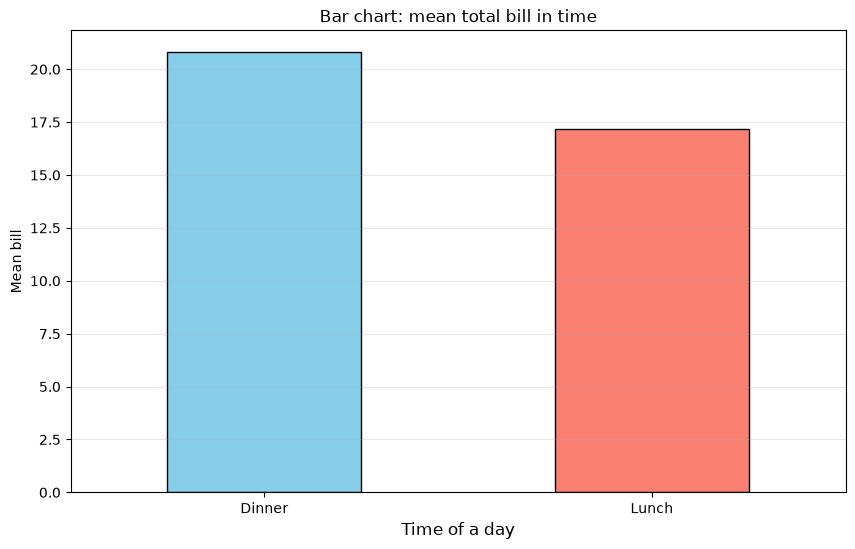

In [34]:
# 4. Bar chart: середній рахунок за часом
# Створіть стовпчасту діаграму середнього рахунку за часом дня (time).
df.groupby("time")["total_bill"].mean().plot(kind="bar", figsize=(10, 6), color=['skyblue', 'salmon'], edgecolor="black")
plt.title("Bar chart: mean total bill in time")
plt.xlabel("Time of a day", fontsize=12)
plt.ylabel("Mean bill")
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [26]:
# 5. Інтерактивна діаграма розсіювання
# Створіть з допомогою бібліотек Plotly інтерактивний scatter plot для total_bill vs tip з кольором за статтю (sex).
fig = px.scatter(df, x="total_bill", y="tip", color="sex",
                title="Total bill & tips",
                size='size',  # Розмір точки = розмір групи
                hover_data=['day', 'time'],
                labels={"total_bill": "Total bill ($)", "tip": "Tips ($)", "sex": "Gender", 'size': 'Розмір групи'},
                color_continuous_scale="RdYlGn")
fig.show()

In [30]:
# 6. Інтерактивний box plot: чайові за днями та статтю
# Створіть інтерактивний box plot для чайових за днями тижня з розбивкою за кольором по статі.
fig = px.box(df, x="day", y="tip", color="sex",
             title="Tips by Day",
             labels={"tip": "Tip ($)", "day": "Day", "sex": "Gender"},
             category_orders={'day': ['Thur', 'Fri', 'Sat', 'Sun']}
    
             )
fig.show()